## A/B Testing, Randomized Controlled Trials

- We want to estimate the **average treatment effect**: The average difference in outcomes between the treatment and control groups
- Remember, the stakes are something like: If we implement this intervention at the scale of millions of patients, how many lives are:
    - Saved because the treatment works and our experiment showed it did (Good)
    - Not lost because the treatment doesn't work and our experiment showed it doesn't work (Good)
    - Not saved because the treatment works but our experiment failed to show it did (Bad)
    - Lost because the treatment actually harms patients, but our experiment falsely suggested it works (Very bad)

In [88]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

We generally can't compare what would have happened to observation $i$, if they had been assigned to the other treatment. This means we only observe
$$
y_{iA} = \text{Outcome for $i$ receiving treatment $A$ }
$$
or
$$
y_{iB} = \text{Outcome for $i$ receiving treatment $B$ }
$$
but not both. The **average outcome** for group $A$ is
$$
\frac{1}{\text{Size of group } A} \sum_{i \text{ receiving } A} y_{iA}
$$
and the **average outcome** for group $B$ is
$$
\frac{1}{\text{Size of group } B} \sum_{i \text{ receiving } B} y_{iB}.
$$
When we difference them, we get the **Average Treatment Effect (ATE)**:
$$
ATE = \dfrac{1}{\text{Size of group } A} \sum_{i \text{ receiving } A} y_{iA} \quad - \quad \frac{1}{\text{Size of group } B} \sum_{i \text{ receiving } B} y_{iB}
$$
As long as treatment is randomly assigned, there is no reason to think that the participants in group $A$ or $B$ are systematically different, and the **ATE** is an unbiased estimator of the true contrast in outcomes between groups $B$ and $A$. We "average away" the differences across the two groups to get an estimate of the difference in outcomes.

We then use bootstrapping to do two things:

1. Estimate the density/distribution for the averages outcomes in both groups
2. Estimate the ATE and its density/distribution

## Part 1

- First, we're going to evaluate a particular clinical trial, on chronic kidney disease:
    - ISCHEMIA-Chronic Kidney Disease Trial (ISCHEMIA-CKD)
    - ClinicalTrials.gov ID NCT01985360
    - Sponsor NYU Langone Health
    - Information provided by NYU Langone Health (Responsible Party)
- The study compared a "routine invasive therapy" (intra-aortic balloon pumps) intended to reduce death/heart attack versus more conservative medical interventions during heart surgery

<div>
<img src="./src/ischemia.png" width="700"/>
</div>

**1.** Load the `./data/iabp.csv` data. Cross tabulate `Group` and `Survived`. What is the point estimate of the ATE? Would you rather get the intra aortic balloon pump or not? Remember, **Invasive** means pump and **Conservative** means not.
- I would not get the pump as it seems ineffective as the ATE = -.01. So the control group has a 1% higher chance of survival. With the ATE being so close to zero also I would not be convinced to get the surgery and trust it to be worth it.

In [89]:
df = pd.read_csv('./data/iabp.csv')

## Crosstabs, average treatment effect:
print(pd.crosstab( df['Group'], df['Survived']), '\n')

ate = df.loc[ df['Group'] == 'Invasive', 'Survived'].mean() \
    - df.loc[ df['Group'] == 'Conservative', 'Survived'].mean() 
print('Estimated ATE: ', np.round(ate, 3))

Survived      0.0  1.0
Group                 
Conservative  291   98
Invasive      294   94 

Estimated ATE:  -0.01


**2.** Bootstrap the average outcome for group A, the average outcome for group B, and difference then to get the ATE, 10,000 times. Store all of these estimates. This is important: **Bootstrap the two groups separately, since this is a clinical trial and there was random assignment (we want to maintain the balance across treatment arms because that maximizes statistical power)**.

In [90]:
## Bootstrapping:
R = 10_000

df_a = df.loc[ df['Group'] == 'Invasive',:]
df_b = df.loc[ df['Group'] == 'Conservative',:]

outcome_a = []
outcome_b = []
ate = [] # Store computed effects

for t in range(R):
    ## Resample:
    df_at = df_a.sample(frac=1.0, replace=True)
    df_bt = df_b.sample(frac=1.0, replace=True)

    ## Evaluate outcomes:
    oat = df_at['Survived'].mean() # Mean outcome for A
    obt = df_bt['Survived'].mean() # Mean outcome for B    

    ## Compute ATE:
    ate_t = oat - obt # Compute ATE for this bootstrap sample
    
    ## Store results:
    outcome_a.append(oat) # Save new value
    outcome_b.append(obt) # Save new value
    ate.append(ate_t) # Save new value

**3.** Make a plot of the KDEs of the outcomes for the two groups, and a plot of the ECDFs for the two groups. What relationships do you see between the two groups?
- The conservative approach seems to have a higher survival rate by a slight edge. The KDE is further to the right and the ECDF appears almost entirely underneath the invasive curve. 

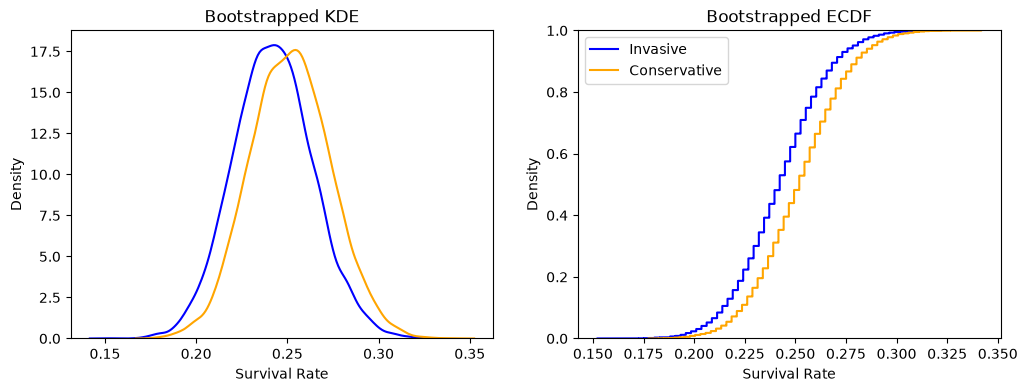

In [91]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))

sns.kdeplot(outcome_a, label='Invasive', color='blue', ax=ax[0])
sns.kdeplot(outcome_b, label='Conservative', color='orange', ax=ax[0]).set(title='Bootstrapped KDE', xlabel='Survival Rate', ylabel='Density')

sns.ecdfplot(outcome_a, label='Invasive', color='blue', ax=ax[1])
sns.ecdfplot(outcome_b, label='Conservative', color='orange', ax=ax[1]).set(title='Bootstrapped ECDF', xlabel='Survival Rate', ylabel='Density')

plt.legend()
plt.show()

**4.** Make a plot of the KDE and ECDF for the ATE. Does it have a roughly bell shape? What range of values are possible for this intervention?
- Yes this is roughly bell sahped and the range is -.12 to .098

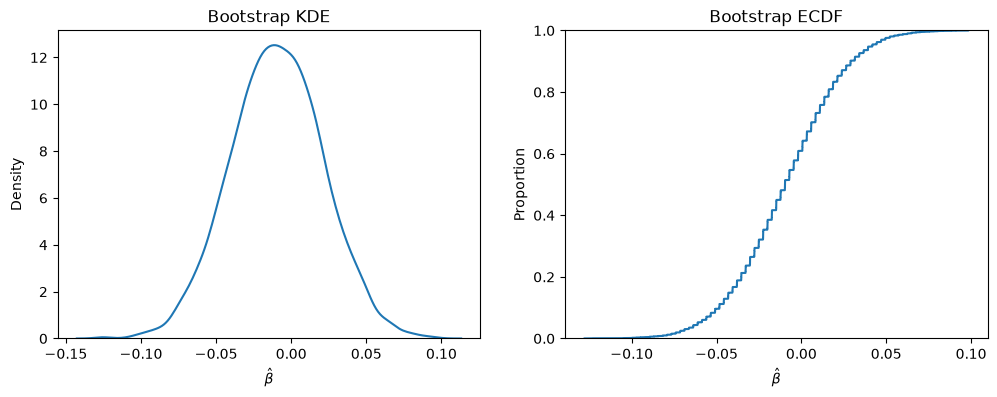

In [92]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))

## KDE
sns.kdeplot(ate, ax=ax[0])
ax[0].set_xlabel(r"$\hat{\beta}$")
ax[0].set_title("Bootstrap KDE")

## ECDF
sns.ecdfplot(ate, ax=ax[1])
ax[1].set_xlabel(r"$\hat{\beta}$")
ax[1].set_title("Bootstrap ECDF")

plt.show()


In [114]:
print(np.min(ate))
print(np.max(ate))

-0.1280245408528344
0.09841518034611613


**5.** Compute 90%, 95%, and 99% confidence intervals for the ATE. Is zero in those intervals? For which do we "fail to reject the null hypothesis that the effect size is zero" and for which do we "reject the null hypothesis that the effect size is zero"?
- Zero is within all of the intervals so we fail to reject at every level. 

In [93]:
ci90 = np.quantile(ate, [.05, .95])
ci95 = np.quantile(ate, [.025, .975])
ci99 = np.quantile(ate, [.005, .995])

print(f"90% CI: {ci90}")
print(f"95% CI: {ci95}")
print(f"99% CI: {ci99}")

90% CI: [-0.06111395  0.04180028]
95% CI: [-0.06892541  0.04957216]
99% CI: [-0.0894575   0.07014417]


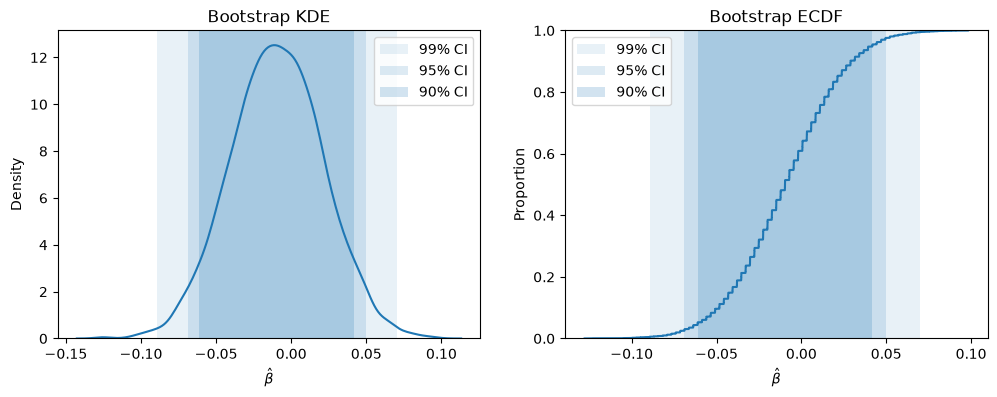

In [94]:
# Percentile bootstrap confidence intervals
ci90 = np.quantile(ate, [.05, .95])
ci95 = np.quantile(ate, [.025, .975])
ci99 = np.quantile(ate, [.005, .995])

fig, ax = plt.subplots(1, 2, figsize=(12, 4))

## KDE
sns.kdeplot(ate, ax=ax[0])

ax[0].axvspan(ci99[0], ci99[1], alpha=0.10, label="99% CI")
ax[0].axvspan(ci95[0], ci95[1], alpha=0.15, label="95% CI")
ax[0].axvspan(ci90[0], ci90[1], alpha=0.20, label="90% CI")

ax[0].set_xlabel(r"$\hat{\beta}$")
ax[0].set_title("Bootstrap KDE")
ax[0].legend()

## ECDF
sns.ecdfplot(ate, ax=ax[1])

ax[1].axvspan(ci99[0], ci99[1], alpha=0.10, label="99% CI")
ax[1].axvspan(ci95[0], ci95[1], alpha=0.15, label="95% CI")
ax[1].axvspan(ci90[0], ci90[1], alpha=0.20, label="90% CI")

ax[1].set_xlabel(r"$\hat{\beta}$")
ax[1].set_title("Bootstrap ECDF")
ax[1].legend()

**6.** What have we learned about inserting balloons into hearts?
- It is an invasive procedure with no benefit and gives a 1% decrease in survival rate on average.

# Part 2

In `./data/diabetes.csv`, there is data from a clinical trial considering three treatments for pre-diabetics to reduce the progression to full diabetes: metformin, rosiglitazone, and lifestyle adjustments (diet, exercise). Unlike Part 1, there aren't two treatment arms (i.e. A = aortic balloon, B = no aortic balloon), but three (met, rosi, lifestyle).

You are a data analyst working for `clinicaltrials.gov` and the FDA to provide an unbiased review of the trial's results. The researchers have provided you with `./data/diabests.csv`.

In an ipynb or py file:

1. Load the `./data/diabetes.csv` data. Cross tabulate the outcomes for the three groups. What are the average outcomes for the three groups? 
2. Bootstrap the outcomes for the three groups 10,000 times. Store all of these estimates. As this is another randomized controlled trial, do the resampling within the arms. 
3. Plot the three densities on one plot and three distributions on another. Describe any patterns you see.
4. There are three treatment effects: met versus rosi, met versus lifestyle, rosi versus lifestyle. Make KDE and ECDF plots of all these comparisons.
5. Compute confidence intervals for each pairwise ATE based on its ECDF (percentile bootstrap). Do you find any statistically significant differences between the interventions? Which seems the most effective?

Then:

6. Write a short report (3-5 paragraphs) that summarizes the evidence from the trial for adopting each of the interventions or not. Use tables and visualizations. Write in a professional tone for a technical audience, and focus on evidence (or the lack thereof). Do not assume anyone has read your work in your notebooks.

#### 1. Load the `./data/diabetes.csv` data. Cross tabulate the outcomes for the three groups. What are the average outcomes for the three groups? 

In [95]:
df = pd.read_csv('./data/diabetes.csv', index_col=0)
df['outcome'] = df['outcome'].map({'success': 1, 'failure': 0})

print(df.head(), '\n')
print(pd.crosstab(df['treatment'], df['outcome']))

rates = df.groupby('treatment')['outcome'].mean()
print(rates)


   treatment  outcome
1        met        1
2       rosi        0
3       rosi        1
4  lifestyle        1
5        met        1 

outcome      0    1
treatment          
lifestyle  109  125
met        120  112
rosi        90  143
treatment
lifestyle    0.534188
met          0.482759
rosi         0.613734
Name: outcome, dtype: float64


In [96]:
ate_met_rosi  = rates['met']  - rates['rosi']
ate_met_life  = rates['met']  - rates['lifestyle']
ate_rosi_life = rates['rosi'] - rates['lifestyle']

print(ate_met_rosi)
print(ate_met_life)
print(ate_rosi_life)

-0.13097528488974391
-0.051429413498378984
0.07954587139136493


#### 2. Bootstrap the outcomes for the three groups 10,000 times. Store all of these estimates. As this is another randomized controlled trial, do the resampling within the arms. 

In [97]:
## Bootstrapping:
R = 10_000

df_met  = df.loc[df['treatment'] == 'met', :]
df_rosi = df.loc[df['treatment'] == 'rosi', :]
df_life = df.loc[df['treatment'] == 'lifestyle', :]

outcome_met  = []
outcome_rosi = []
outcome_life = []
boot_met_rosi  = []  # Store computed effects
boot_met_life  = []
boot_rosi_life = []

for t in range(R):
    ## Resample each arm separately:
    df_mt = df_met.sample(frac=1.0, replace=True)
    df_rt = df_rosi.sample(frac=1.0, replace=True)
    df_lt = df_life.sample(frac=1.0, replace=True)

    ## Evaluate outcomes:
    omt = df_mt['outcome'].mean()  # Mean outcome for met
    ort = df_rt['outcome'].mean()  # Mean outcome for rosi
    olt = df_lt['outcome'].mean()  # Mean outcome for lifestyle

    ## Store results:
    outcome_met.append(omt)
    outcome_rosi.append(ort)
    outcome_life.append(olt)
    boot_met_rosi.append(omt - ort)
    boot_met_life.append(omt - olt)
    boot_rosi_life.append(ort - olt)

#### 3. Plot the three densities on one plot and three distributions on another. Describe any patterns you see.

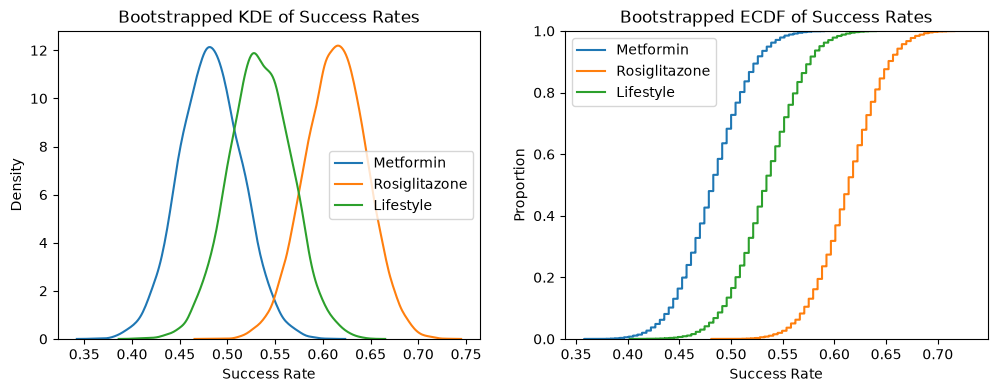

In [98]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))

## Densities
sns.kdeplot(outcome_met,  label='Metformin',     ax=ax[0])
sns.kdeplot(outcome_rosi, label='Rosiglitazone', ax=ax[0])
sns.kdeplot(outcome_life, label='Lifestyle',     ax=ax[0])
ax[0].set(title='Bootstrapped KDE of Success Rates', xlabel='Success Rate', ylabel='Density')
ax[0].legend()

## Distributions
sns.ecdfplot(outcome_met,  label='Metformin',     ax=ax[1])
sns.ecdfplot(outcome_rosi, label='Rosiglitazone', ax=ax[1])
sns.ecdfplot(outcome_life, label='Lifestyle',     ax=ax[1])
ax[1].set(title='Bootstrapped ECDF of Success Rates', xlabel='Success Rate', ylabel='Proportion')
ax[1].legend()

plt.show()

In [115]:
print(np.mean(outcome_met), np.mean(outcome_rosi), np.mean(outcome_life))
print(np.std(outcome_met), np.std(outcome_rosi), np.std(outcome_life))
df['treatment'].value_counts()


0.4825931034482759 0.6134626609442061 0.5340504273504273
0.03275230356513615 0.031938542081018824 0.03295488739118805


treatment
lifestyle    234
rosi         233
met          232
Name: count, dtype: int64

- Peaks
    - Metformmin seems to be the least effective with a success rate right below 50% (.482)
    - Lifestyle changes then seems to be the second most successful with a success rate around 53% (.534)
    - Rosiglitzone seems to be the most effective with an a success rate of 61% (.6134)
- Standard Deviation
    - All three have very similar standard errors around 0.032 and all of the samples are very close together so they are measured with similar precision. 
- Overlap
    - Metformin and Rosiglitzone barely overlap so this pair is likely to show a large difference in ATE
    - The other combinations of Metformin and Lifestyle and Rosiglitzone overlap heavily so there will likely be some indistinguishability between the two ATEs
- Shape
    - The about 230/699 for each treatment gave us about a bell shape and with the resampling the curve became smoother.

#### 4. There are three treatment effects: met versus rosi, met versus lifestyle, rosi versus lifestyle. Make KDE and ECDF plots of all these comparisons.

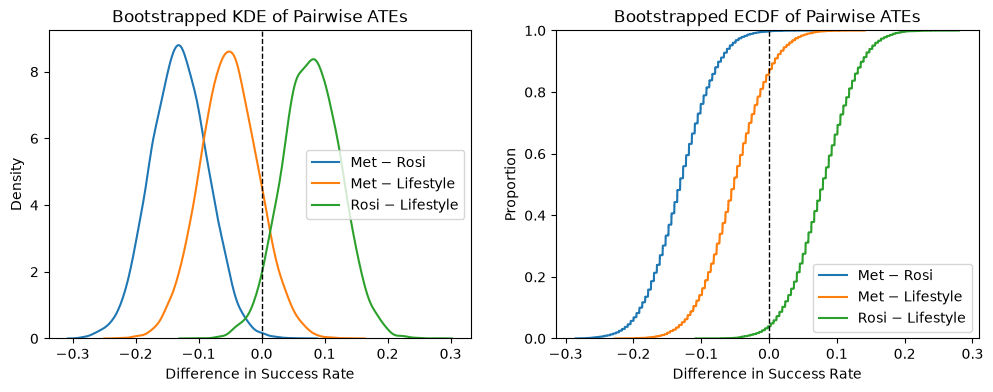

In [108]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))

## KDEs of the pairwise ATEs
sns.kdeplot(boot_met_rosi,  label='Met − Rosi',       ax=ax[0])
sns.kdeplot(boot_met_life,  label='Met − Lifestyle',  ax=ax[0])
sns.kdeplot(boot_rosi_life, label='Rosi − Lifestyle', ax=ax[0])
ax[0].axvline(0, color='black', linestyle='--', linewidth=1)
ax[0].set(title='Bootstrapped KDE of Pairwise ATEs', xlabel='Difference in Success Rate', ylabel='Density')
ax[0].legend()

## ECDFs of the pairwise ATEs
sns.ecdfplot(boot_met_rosi,  label='Met − Rosi',       ax=ax[1])
sns.ecdfplot(boot_met_life,  label='Met − Lifestyle',  ax=ax[1])
sns.ecdfplot(boot_rosi_life, label='Rosi − Lifestyle', ax=ax[1])
ax[1].axvline(0, color='black', linestyle='--', linewidth=1)
ax[1].set(title='Bootstrapped ECDF of Pairwise ATEs', xlabel='Difference in Success Rate', ylabel='Proportion')
ax[1].legend()

plt.show()

#### 5. Compute confidence intervals for each pairwise ATE based on its ECDF (percentile bootstrap). Do you find any statistically significant differences between the interventions? Which seems the most effective?

In [112]:
#Met-Rosi
ci90 = np.quantile(boot_met_rosi, [.05, .95])
ci95 = np.quantile(boot_met_rosi, [.025, .975])
ci99 = np.quantile(boot_met_rosi, [.005, .995])
met_rosi_ci = [ '90%' + str(ci90), '95%' + str(ci95), '99%' + str(ci99) ]

#Met-Lifestyle
ci90 = np.quantile(boot_met_life, [.05, .95])
ci95 = np.quantile(boot_met_life, [.025, .975])
ci99 = np.quantile(boot_met_life, [.005, .995])
met_life_ci = [ '90%' + str(ci90), '95%' + str(ci95), '99%' + str(ci99) ]

#Rosi-Lifestyle
ci90 = np.quantile(boot_rosi_life, [.05, .95])
ci95 = np.quantile(boot_rosi_life, [.025, .975])
ci99 = np.quantile(boot_rosi_life, [.005, .995])
rosi_life_ci = [ '90%' + str(ci90), '95%' + str(ci95), '99%' + str(ci99) ]

print('Met-Rosi', met_rosi_ci)
print('Met-Lifestyle', met_life_ci)
print('Rosi-Lifestyle', rosi_life_ci)


Met-Rosi ['90%[-0.20412258 -0.0577725 ]', '95%[-0.22114196 -0.04077253]', '99%[-0.25140604 -0.01065552]']
Met-Lifestyle ['90%[-0.12857353  0.02586207]', '95%[-0.14168969  0.04277188]', '99%[-0.1713456  0.0688922]']
Rosi-Lifestyle ['90%[0.00662026 0.1524348 ]', '95%[-0.01034445  0.16938163]', '99%[-0.04036903  0.19522404]']


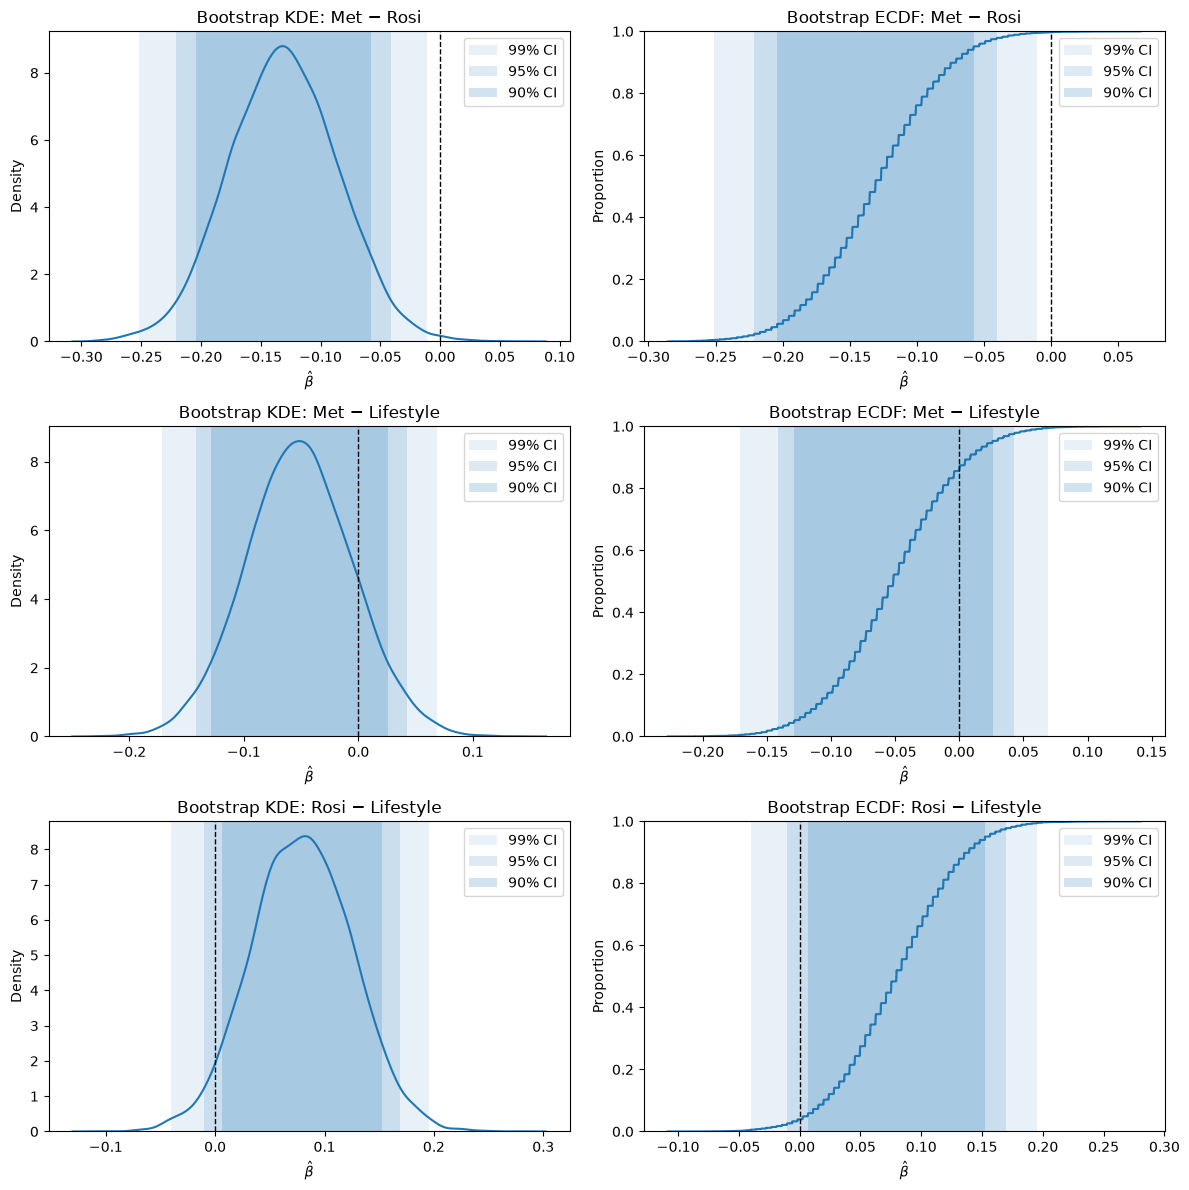

In [113]:
# Percentile bootstrap confidence intervals for each pairwise ATE
comparisons = [('Met − Rosi',       boot_met_rosi),
               ('Met − Lifestyle',  boot_met_life),
               ('Rosi − Lifestyle', boot_rosi_life)]

fig, ax = plt.subplots(3, 2, figsize=(12, 12))

for i, (name, a) in enumerate(comparisons):
    ci90 = np.quantile(a, [.05, .95])
    ci95 = np.quantile(a, [.025, .975])
    ci99 = np.quantile(a, [.005, .995])

    ## KDE
    sns.kdeplot(a, ax=ax[i, 0])
    ax[i, 0].axvspan(ci99[0], ci99[1], alpha=0.10, label="99% CI")
    ax[i, 0].axvspan(ci95[0], ci95[1], alpha=0.15, label="95% CI")
    ax[i, 0].axvspan(ci90[0], ci90[1], alpha=0.20, label="90% CI")
    ax[i, 0].axvline(0, color='black', linestyle='--', linewidth=1)
    ax[i, 0].set_xlabel(r"$\hat{\beta}$")
    ax[i, 0].set_title(f"Bootstrap KDE: {name}")
    ax[i, 0].legend()

    ## ECDF
    sns.ecdfplot(a, ax=ax[i, 1])
    ax[i, 1].axvspan(ci99[0], ci99[1], alpha=0.10, label="99% CI")
    ax[i, 1].axvspan(ci95[0], ci95[1], alpha=0.15, label="95% CI")
    ax[i, 1].axvspan(ci90[0], ci90[1], alpha=0.20, label="90% CI")
    ax[i, 1].axvline(0, color='black', linestyle='--', linewidth=1)
    ax[i, 1].set_xlabel(r"$\hat{\beta}$")
    ax[i, 1].set_title(f"Bootstrap ECDF: {name}")
    ax[i, 1].legend()

plt.tight_layout()
plt.show()

In [116]:
summary = pd.DataFrame({
    'n': df.groupby('treatment')['outcome'].count(),
    'successes': df.groupby('treatment')['outcome'].sum(),
    'success_rate': rates.round(3),
    'bootstrap_SE': [np.std(outcome_life), np.std(outcome_met), np.std(outcome_rosi)],
}).round(3)
summary

,n,successes,success_rate,bootstrap_SE
treatment,,,,
lifestyle,234,125,0.534,0.033
met,232,112,0.483,0.033
rosi,233,143,0.614,0.032


- Met-Rosi
    - All of the confidence intervals are entirely below 0 so we have to reject the null nypothesis of no difference
- Met-Lifestyle
    - 0 is within all of the intervals so we fail to reject the null hypothesis. The data does seem to lean more negative so it is possible that lifestyle has more of an effect, but again we fail to reject due to 0 being in all of the intervals
- Rosi-Lifestyle
    - At the 90% intervals 0 is just barely outside of the interval, but once we go to higher percentages, 0 is within the interval. Similarly to met-lifestyle, Rosi-Lifestyle does seem to go much further in the positive with only a slight area below 0 so it is possible it has more of an effect. 

### 6. Write a short report (3-5 paragraphs) that summarizes the evidence from the trial for adopting each of the interventions or not. Use tables and visualizations. Write in a professional tone for a technical audience, and focus on evidence (or the lack thereof). Do not assume anyone has read your work in your notebooks.

Metformin was given to 232 of the 699 with the outcome of success or failure. The effects were estimated with 10,000 bootstrap resamples drawn within each group and the percentile confidence intervals were used to determine the pairwise differences. The first graph with all three treatments KDE and ECDF success rates shows that it has the lowest success rate right below 50%. The standard deviation is 0.032 which is nearly identical for all of the treatments. With that being said Metformin is not statistically different from lifestyle changes as all of the intervals contain 0. However when compared to Rosiglitazone, we can see that 0 is outside of the interval so it is worse than Rosiglitazone at every level. The same can be said for lifestyle, but 0 is much closer to the center. This trial gives no reason to drop Metformin as upon researching the drug it is cheap and often the first attempted medication for lowering blood sugar. The only evidence we do have is that it is the least effective of the treatments. However, if the first and cheapest medication works, then there is no need to try an alternative medication that could be more expensive or have harsher side effects. 

Rosiglitazonewas given to 233 of the 699 with the same outcome of failure and success. WHen looking at the sample results we see that it is the highest average success rate at about 61%. This is the only treatment with a significant advantage over another treatment. It is about 13% more successful in the sample of 699. In the bootstrap we see that it goes to 58%, which is still about 10% higher than the bootstrap average success rate for Metformin. This result holds at every confidence interval level as every interval for Met-Rosi is below 0. For lifestyle there is less of a clear gap, but Rosi-Lifestyle predominantly produces values that skew positive which suggests Rosiglitazone has a larger impact than lifestyle. given this we have no reason to drop rosiglitazone, but after researching the drug, the side effects can be much more severe compared to Metformin. So I would only adopt this treatment if Metformin had failed and we need to try a different treatment and the negative side effects are outweighed by the positives of the treatment. 

Lifestyle changes has a slightly above 53% success rate and its distribution overlaps with both drugs. The confidence intervals indicate that this is not statistically significant as the 95% and 99% ATE confidence intervals contain 0. However it does show good signs of improvement, but each person's lifestyle is different and therefore each person's lifestyle changes will be different.

Lifestyle changes in addition to the medication seems to be helpful, but as 0 is within the interval it is possible that lifestyle changes will not have an effect on success. The limitation to form a proper conclusion to which drug is superior are, the lack of cost data for the subjects, the side effects and level of severity they underwent. If we can determine the costs and side effects on a per patient level then we can say which drug is better, but from my research, it seems there is no downside to trying the less effective drug with little to no side effects, Metformin, before trying a much harsher, but more successful drug, Rosiglitazone. The best course of action is to try lifestyle improvements while taking Metformin, and if it is not successful, continue the lifestyle changes and try Rosiglitazone.